<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS09/datasetPBL/Praktikum1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

# Load dan gabungkan kedua dataset milikmu
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')
df = pd.merge(df_reviews, df_cafes, on='cafe_id', how='left', suffixes=('_review', '_cafe'))

# Bentuk label target klasifikasi (3 kelas: Rendah, Sedang, Tinggi berdasarkan rating_review)
def kategori_rating(r):
    if r <= 3:
        return 'Rendah'
    elif r == 4:
        return 'Sedang'
    else:
        return 'Tinggi'

fitur = ['rating_review', 'rating_cafe', 'review_count', 'latitude', 'longitude']
data = df[fitur].fillna(0).copy()
data['kategori'] = df['rating_review'].apply(kategori_rating)

data.head()

,rating_review,rating_cafe,review_count,latitude,longitude,kategori
0,5.0,4.7,528,-7.972556,112.622708,Tinggi
1,5.0,4.7,528,-7.972556,112.622708,Tinggi
2,5.0,4.7,528,-7.972556,112.622708,Tinggi
3,5.0,4.7,528,-7.972556,112.622708,Tinggi
4,5.0,4.7,528,-7.972556,112.622708,Tinggi


In [2]:
data.info()
print("\nStatistik Deskriptif:")
print(data.describe())
print("\nDistribusi Kelas Target:")
print(data['kategori'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2230 entries, 0 to 2229
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   rating_review  2230 non-null   float64
 1   rating_cafe    2230 non-null   float64
 2   review_count   2230 non-null   int64  
 3   latitude       2230 non-null   float64
 4   longitude      2230 non-null   float64
 5   kategori       2230 non-null   object 
dtypes: float64(4), int64(1), object(1)
memory usage: 104.7+ KB

Statistik Deskriptif:
       rating_review  rating_cafe  review_count     latitude    longitude
count    2230.000000  2230.000000   2230.000000  2230.000000  2230.000000
mean        4.553363     4.647623    933.663677    -7.964982   112.627947
std         1.076097     0.165432   1225.834779     0.010956     0.007640
min         1.000000     4.200000      1.000000    -7.985575   112.607256
25%         5.000000     4.600000    166.000000    -7.972556   112.622708
50%        

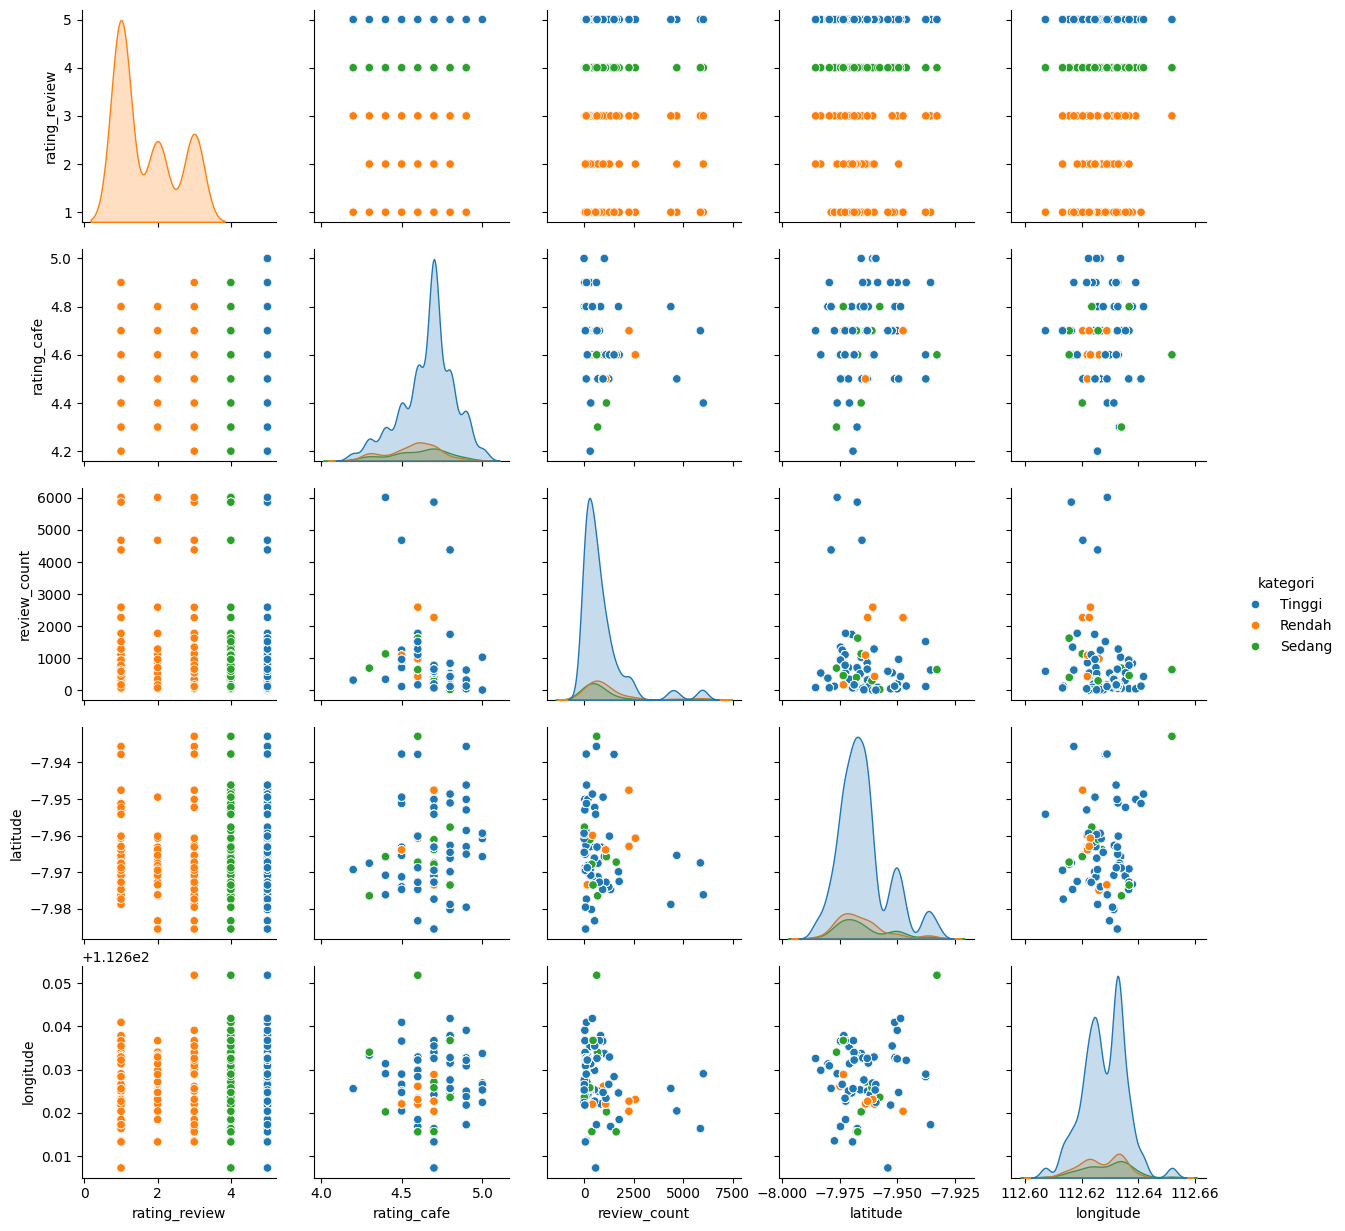

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(data, hue='kategori')
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = data.iloc[:, :-1]   # semua kolom fitur numerik
y = data.iloc[:, -1]    # kolom label terakhir ('kategori')

# Split data (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Standardisasi
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [5]:
from sklearn.neighbors import KNeighborsClassifier

# Tentukan nilai K (misalnya 3)
knn = KNeighborsClassifier(n_neighbors=3)

# Latih model
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

Akurasi: 0.9820627802690582
Confusion Matrix:
 [[ 70   3   0]
 [  6  48   3]
 [  0   0 539]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

      Rendah       0.92      0.96      0.94        73
      Sedang       0.94      0.84      0.89        57
      Tinggi       0.99      1.00      1.00       539

    accuracy                           0.98       669
   macro avg       0.95      0.93      0.94       669
weighted avg       0.98      0.98      0.98       669



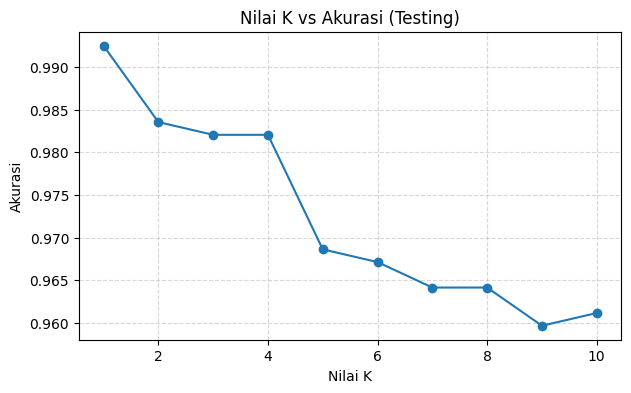

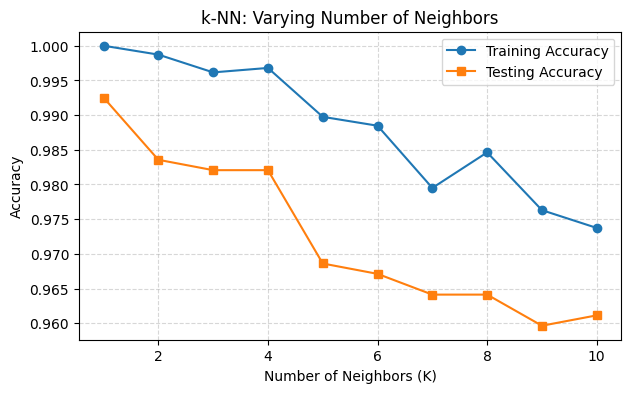

In [6]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = knn.predict(X_test)
print("Akurasi:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

# Evaluasi nilai K = 1 sampai 10 (Testing vs Training)
train_acc = []
test_acc = []
k_range = range(1, 11)

for k in k_range:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    train_acc.append(model.score(X_train, y_train))
    test_acc.append(model.score(X_test, y_test))

# Grafik 1: Nilai K vs Akurasi Testing (sesuai plot pertama di modul)
plt.figure(figsize=(7, 4))
plt.plot(k_range, test_acc, marker='o')
plt.title('Nilai K vs Akurasi (Testing)')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Grafik 2: Perbandingan Akurasi Training vs Testing (sesuai plot kedua di modul)
plt.figure(figsize=(7, 4))
plt.plot(k_range, train_acc, marker='o', label='Training Accuracy')
plt.plot(k_range, test_acc, marker='s', label='Testing Accuracy')
plt.title('k-NN: Varying Number of Neighbors')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()